In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df1 = pd.read_csv(r"C:\Users\dell\Downloads\Unemployment in India.csv")
df2 = pd.read_csv(r"C:\Users\dell\Downloads\Unemployment_Rate_upto_11_2020.csv")

print(df1.shape, df2.shape)
df1.head()

(768, 7) (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [8]:
for d in (df1, df2):
    d.columns = d.columns.str.strip()                                  # column names ke extra spaces hatao
    d.dropna(how="all", inplace=True)                                  # blank rows hatao
    d["Date"] = pd.to_datetime(d["Date"].str.strip(), dayfirst=True)   # date format theek karo (dd-mm-yyyy)
    d["Region"] = d["Region"].str.strip()
    d["Frequency"] = d["Frequency"].str.strip()

# Column ke naam chhote kar do
rename = {
    "Estimated Unemployment Rate (%)": "UnempRate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "LPR",
}
df1.rename(columns=rename, inplace=True)
df2.rename(columns=rename, inplace=True)
df2.rename(columns={"Region.1": "Zone"}, inplace=True)

# Naye columns: mahina aur saal
for d in (df1, df2):
    d["Month"] = d["Date"].dt.month
    d["Month_Name"] = d["Date"].dt.strftime("%b")
    d["Year"] = d["Date"].dt.year

# Check
print(df1.shape, df2.shape)
print("Missing values:", df1.isna().sum().sum(), df2.isna().sum().sum())
print("Duplicates:", df1.duplicated().sum(), df2.duplicated().sum())
df1.head()

(740, 10) (267, 12)
Missing values: 0 0
Duplicates: 0 0


,Region,Date,Frequency,UnempRate,Employed,LPR,Area,Month,Month_Name,Year
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,5,May,2019
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,6,Jun,2019
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,7,Jul,2019
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,8,Aug,2019
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,9,Sep,2019


In [9]:
# 1. Basic info
print(df2.info())
print(df2.describe().round(2))

# 2. State-wise average unemployment (top 10 sab se zyada)
state_avg = df2.groupby("Region")["UnempRate"].mean().sort_values(ascending=False)
print("\nTop 10 states (highest unemployment):")
print(state_avg.head(10).round(2))

print("\nSab se kam 3 states:")
print(state_avg.tail(3).round(2))

# 3. Zone-wise average
print("\nZone-wise average:")
print(df2.groupby("Zone")["UnempRate"].mean().sort_values(ascending=False).round(2))

# 4. Rural vs Urban (df1)
print("\nRural vs Urban:")
print(df1.groupby("Area")["UnempRate"].mean().round(2))

# 5. Correlation
print("\nCorrelation:")
print(df2[["UnempRate", "Employed", "LPR"]].corr().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Region      267 non-null    str           
 1   Date        267 non-null    datetime64[us]
 2   Frequency   267 non-null    str           
 3   UnempRate   267 non-null    float64       
 4   Employed    267 non-null    int64         
 5   LPR         267 non-null    float64       
 6   Zone        267 non-null    str           
 7   longitude   267 non-null    float64       
 8   latitude    267 non-null    float64       
 9   Month       267 non-null    int32         
 10  Month_Name  267 non-null    str           
 11  Year        267 non-null    int32         
dtypes: datetime64[us](1), float64(4), int32(2), int64(1), str(4)
memory usage: 27.9 KB
None
                             Date  UnempRate     Employed     LPR  longitude  \
count                         267     267.00       267.00  26

In [10]:
state_avg = df2.groupby("Region")["UnempRate"].mean().sort_values(ascending=False)

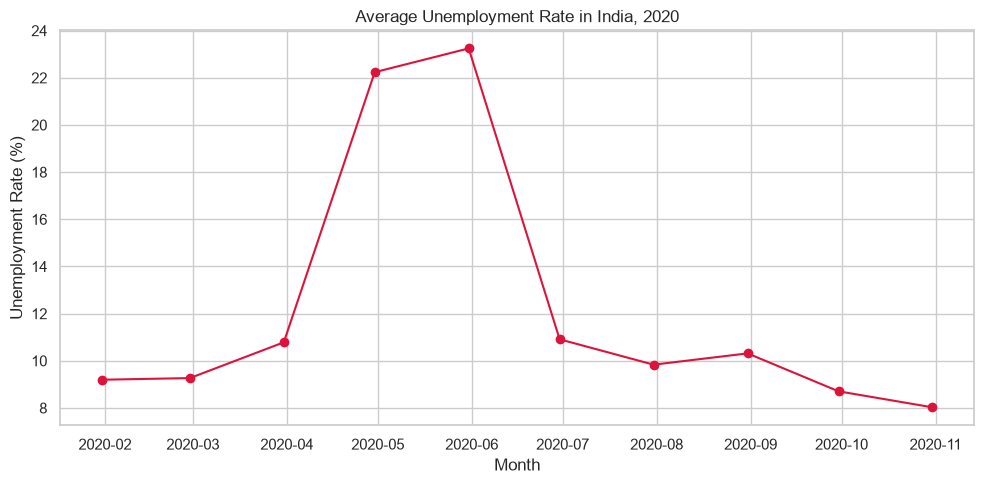

In [11]:
monthly = df2.groupby("Date")["UnempRate"].mean()

plt.figure(figsize=(10,5))
plt.plot(monthly.index, monthly.values, marker="o", color="crimson")
plt.title("Average Unemployment Rate in India, 2020")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

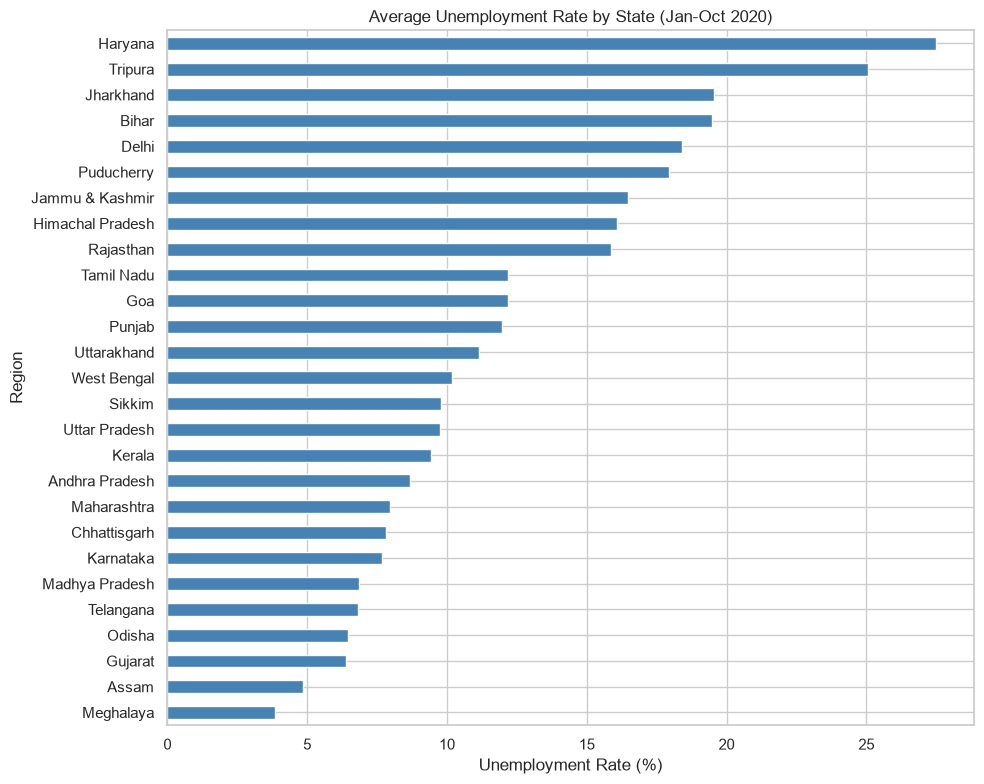

In [12]:
plt.figure(figsize=(10,8))
state_avg.sort_values().plot(kind="barh", color="steelblue")
plt.title("Average Unemployment Rate by State (Jan-Oct 2020)")
plt.xlabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

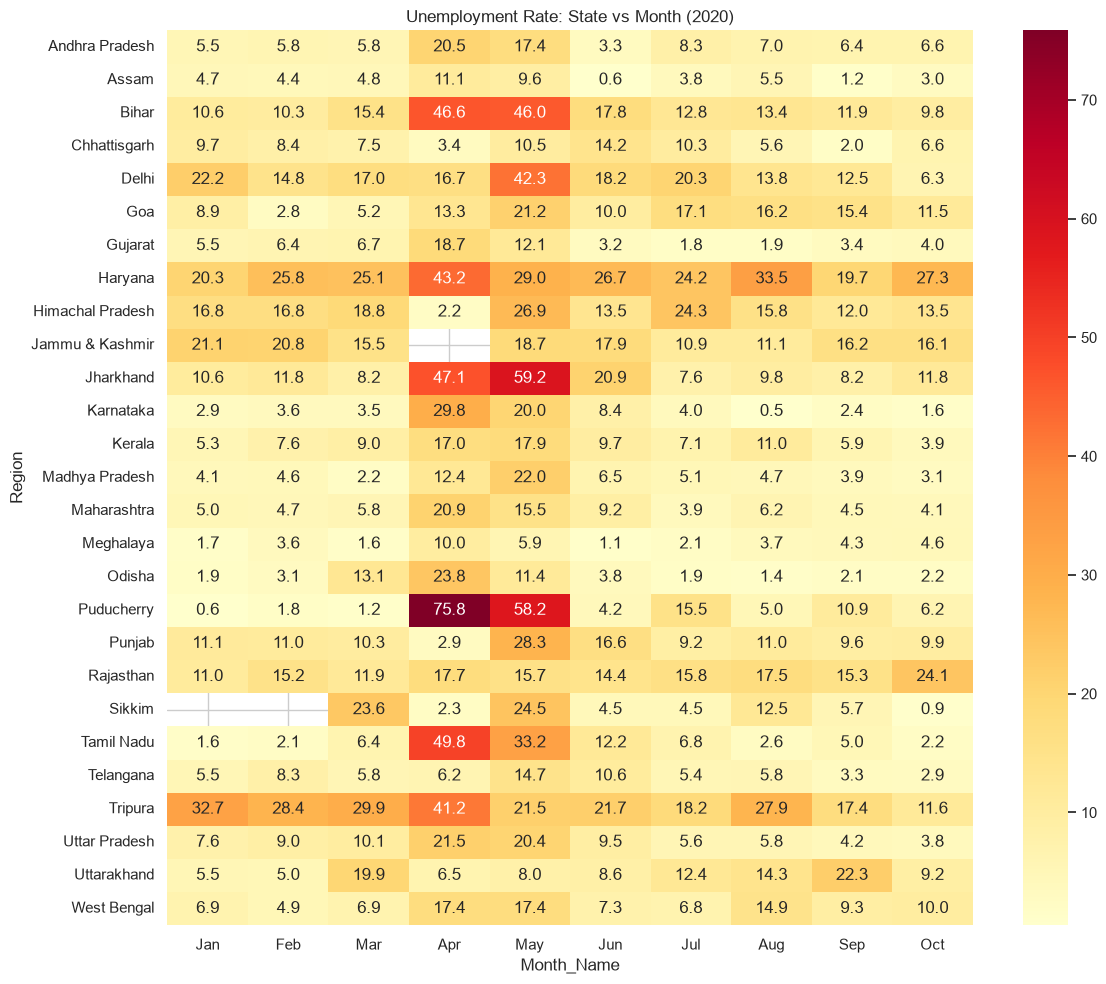

In [13]:
pivot = df2.pivot_table(index="Region", columns="Month_Name", values="UnempRate")
pivot = pivot[["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct"]]

plt.figure(figsize=(12,10))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".1f")
plt.title("Unemployment Rate: State vs Month (2020)")
plt.tight_layout()
plt.show()

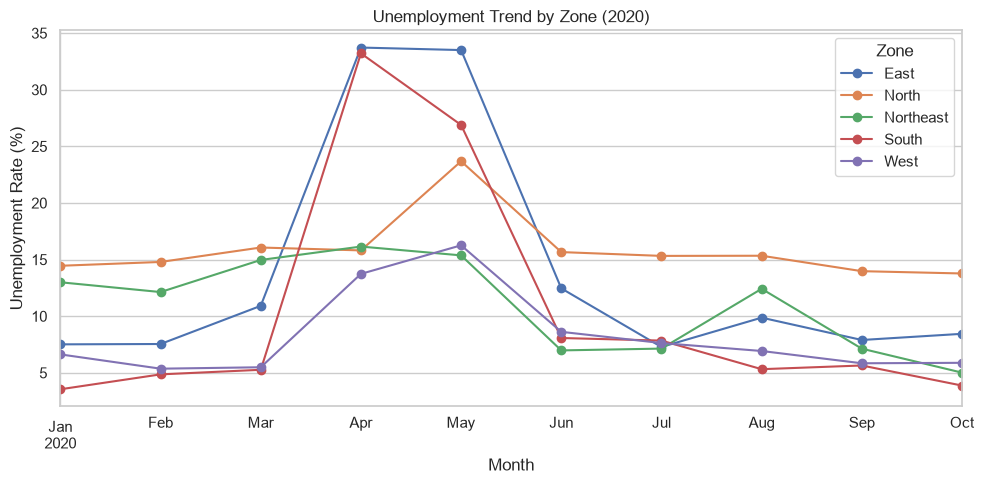

In [14]:
zone_trend = df2.groupby(["Date","Zone"])["UnempRate"].mean().unstack()

zone_trend.plot(figsize=(10,5), marker="o")
plt.title("Unemployment Trend by Zone (2020)")
plt.ylabel("Unemployment Rate (%)")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

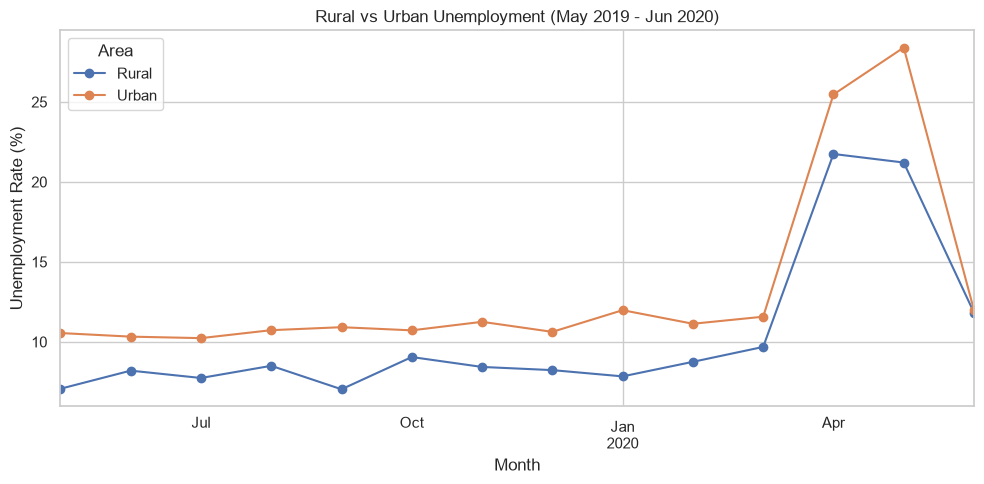

In [15]:
ru = df1.groupby(["Date","Area"])["UnempRate"].mean().unstack()

ru.plot(figsize=(10,5), marker="o")
plt.title("Rural vs Urban Unemployment (May 2019 - Jun 2020)")
plt.ylabel("Unemployment Rate (%)")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

Period
Post-Lockdown    12.96
Pre-Lockdown      9.23
Name: UnempRate, dtype: float64


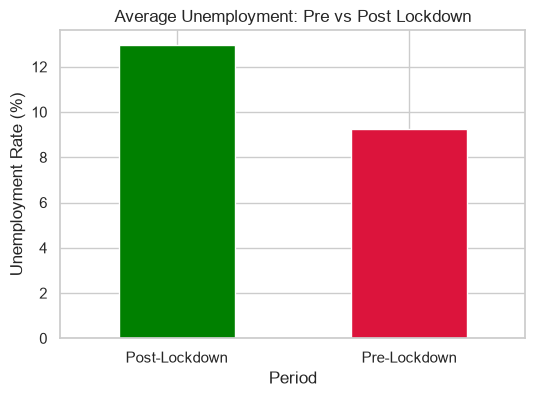

In [16]:
# Lockdown 25 March 2020 ko shuru hua
df2["Period"] = np.where(df2["Date"] < "2020-03-25", "Pre-Lockdown", "Post-Lockdown")
print(df2.groupby("Period")["UnempRate"].mean().round(2))

df2.groupby("Period")["UnempRate"].mean().plot(kind="bar", color=["green", "crimson"], figsize=(6,4))
plt.title("Average Unemployment: Pre vs Post Lockdown")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.show()

Region
Puducherry        74.68
Tamil Nadu        48.00
Bihar             36.19
Jharkhand         35.86
Karnataka         26.60
Odisha            21.25
Haryana           20.16
Maharashtra       16.08
Andhra Pradesh    14.86
Uttar Pradesh     13.26
Name: UnempRate, dtype: float64


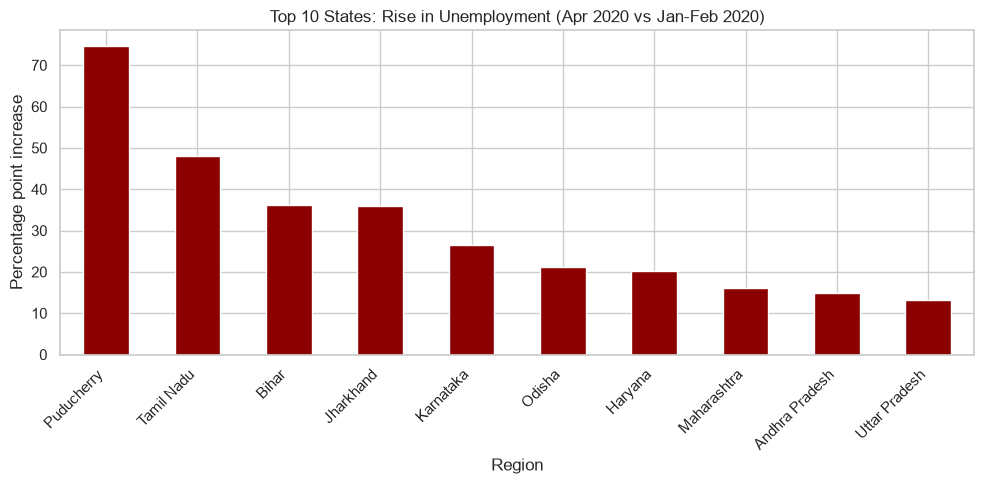

In [17]:
pre  = df2[df2["Month"].isin([1,2])].groupby("Region")["UnempRate"].mean()
peak = df2[df2["Month"] == 4].groupby("Region")["UnempRate"].mean()
impact = (peak - pre).sort_values(ascending=False)
print(impact.head(10).round(2))

impact.head(10).plot(kind="bar", color="darkred", figsize=(10,5))
plt.title("Top 10 States: Rise in Unemployment (Apr 2020 vs Jan-Feb 2020)")
plt.ylabel("Percentage point increase")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

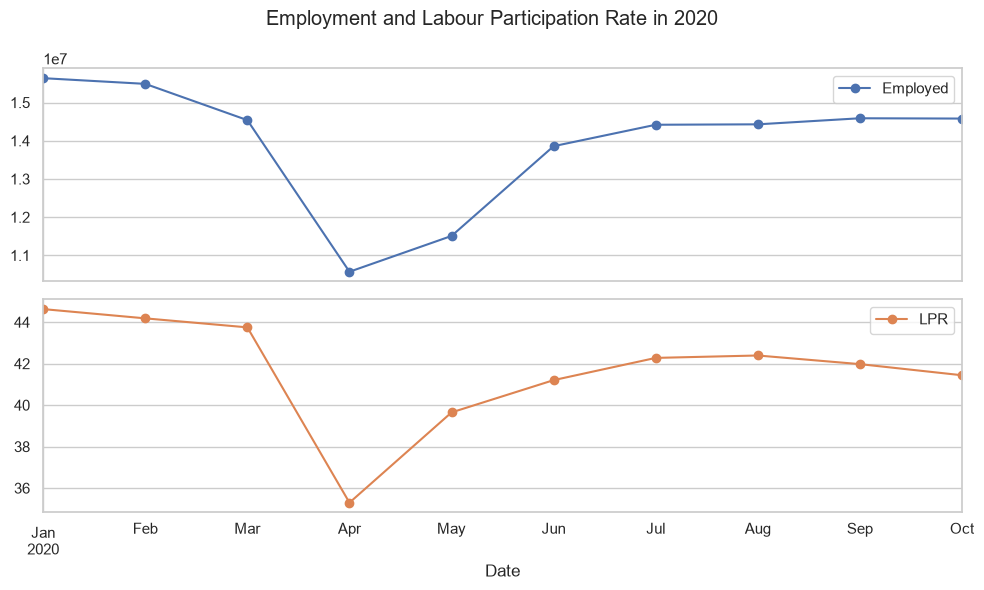

In [18]:
df2.groupby("Date")[["Employed", "LPR"]].mean().plot(subplots=True, figsize=(10,6), marker="o")
plt.suptitle("Employment and Labour Participation Rate in 2020")
plt.tight_layout()
plt.show()

Area   Period       
Rural  Post-Lockdown    16.18
       Pre-Lockdown      8.09
Urban  Post-Lockdown    19.28
       Pre-Lockdown     10.84
Name: UnempRate, dtype: float64


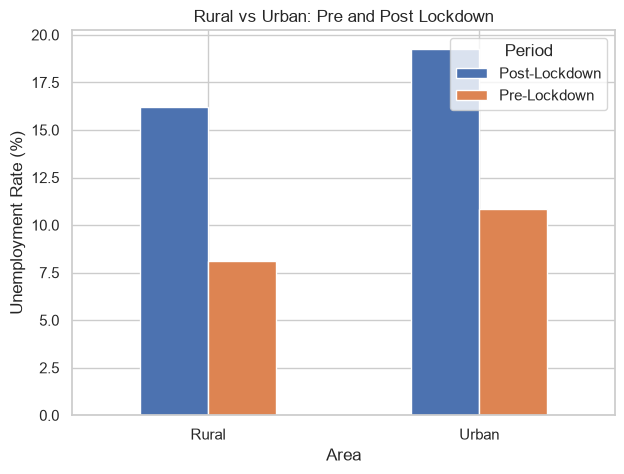

In [19]:
df1["Period"] = np.where(df1["Date"] < "2020-03-25", "Pre-Lockdown", "Post-Lockdown")
print(df1.groupby(["Area", "Period"])["UnempRate"].mean().round(2))

df1.groupby(["Area", "Period"])["UnempRate"].mean().unstack().plot(kind="bar", figsize=(7,5))
plt.title("Rural vs Urban: Pre and Post Lockdown")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.show()

Year   2019   2020
Month             
1       NaN   9.95
2       NaN   9.96
3       NaN  10.70
4       NaN  23.64
5      8.87  24.88
6      9.30  11.90
7      9.03    NaN
8      9.64    NaN
9      9.05    NaN
10     9.90    NaN
11     9.87    NaN
12     9.50    NaN


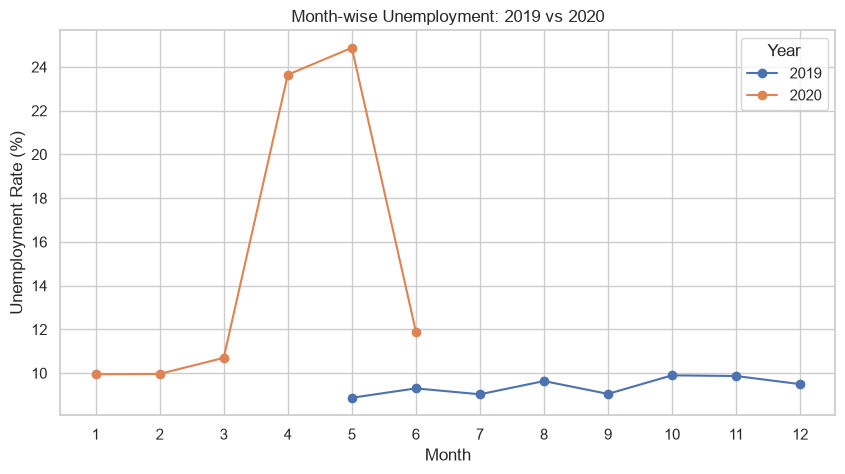

In [20]:
seasonal = df1.groupby(["Year", "Month"])["UnempRate"].mean().unstack(0)
print(seasonal.round(2))

seasonal.plot(figsize=(10,5), marker="o")
plt.title("Month-wise Unemployment: 2019 vs 2020")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(range(1, 13))
plt.show()

Area   Rural  Urban
Month              
5       7.07  10.55
6       8.20  10.33
7       7.74  10.23
8       8.50  10.73
9       7.04  10.92
10      9.05  10.72
11      8.43  11.25
12      8.23  10.63


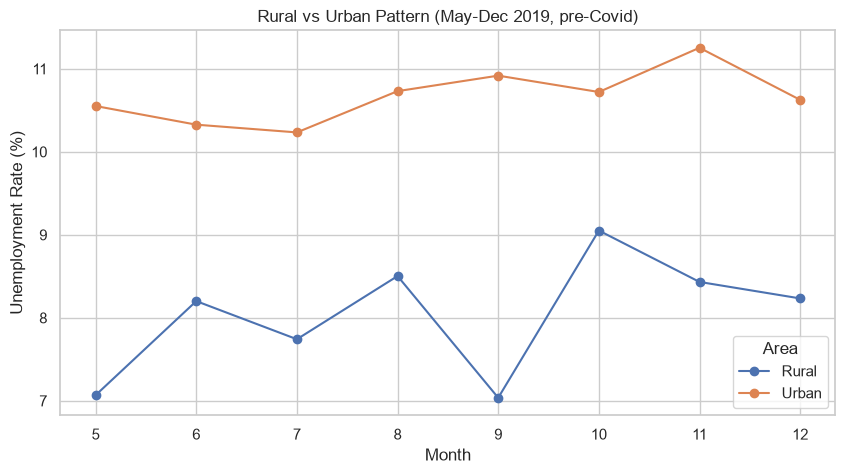

In [21]:
normal = df1[df1["Year"] == 2019]
pattern = normal.groupby(["Month", "Area"])["UnempRate"].mean().unstack()
print(pattern.round(2))

pattern.plot(figsize=(10,5), marker="o")
plt.title("Rural vs Urban Pattern (May-Dec 2019, pre-Covid)")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.show()

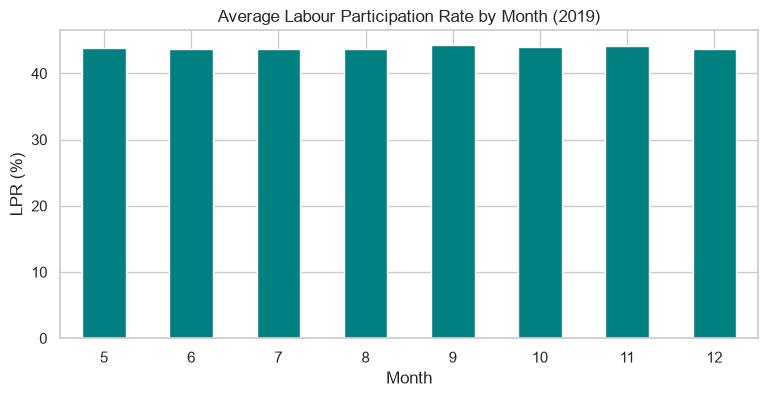

In [22]:
lpr = normal.groupby("Month")["LPR"].mean()
lpr.plot(kind="bar", color="teal", figsize=(9,4))
plt.title("Average Labour Participation Rate by Month (2019)")
plt.ylabel("LPR (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
Step 7: Key Insights aur Policy Recommendations

Key Findings

1. Covid-19 lockdown ka bohat bara asar:
Lockdown se pehle (Jan-Feb 2020) average unemployment rate ~9.2% thi. April 2020 mein ye barh kar ~22.2% aur May 2020 mein ~23.2% ho gayi, yani 2.5 guna se zyada izafa.

2. Rozgar aur labour participation dono gire:
Average employed log ~15.6 million (Jan) se gir kar ~10.6 million (April) reh gaye. Labour Participation Rate 45% se gir kar 35% ho gayi, yani bohat se log kaam dhoondna hi chhor gaye.

3. Recovery:
June 2020 se tezi se recovery hui aur October 2020 tak average rate ~8.0% par aa gayi, jo lockdown se pehle ke level se bhi kam hai.

4. Sab se zyada mutasir states (April vs Jan-Feb):
Puducherry (+74.7 points), Tamil Nadu (+48.0), Bihar (+36.2), Jharkhand (+35.9), Karnataka (+26.6).

5. Zones:
North (15.9%) aur East (13.9%) mein sab se zyada berozgari rahi, West (8.2%) mein sab se kam.

6. Rural vs Urban:
Dono mein berozgari lagbhag double hui (Rural: 8.1% se 16.2%, Urban: 10.8% se 19.3%). Urban areas mein berozgari poore arse mein rural se zyada rahi.

7. Seasonal pattern:
Covid se pehle (May-Dec 2019) rate 8.9% se 9.9% ke beech stable rahi, is liye koi wazeh mausmi pattern nahi mila. April-May 2020 ka spike mausmi nahi, balki lockdown ki wajah se tha.

Policy Recommendations

1. Urban areas ke liye unemployment insurance aur cash transfers**, kyunke shehron mein asar zyada tha.
2. Rural areas mein MGNREGA jaisi employment schemes ko barhana**, taake dehi berozgari mein foran kaam mile.
3. Targeted relief packages** un states ke liye jo sab se zyada mutasir hue (Puducherry, Tamil Nadu, Bihar, Jharkhand).
4. Daily-wage aur informal workers ke liye social security net**, kyunke ye log sab se pehle rozgar kho dete hain.
5. MSME sector ko support** (aasan qarze, tax relief), taake lockdown ke baad jaldi hiring ho sake.
6. Skill development aur reskilling programs**, khaas taur par un logon ke liye jo labour force se bahar nikal gaye.
7. Early warning system:** monthly unemployment data ki monitoring, taake aainda kisi bohran mein jaldi action liya ja sake.

 Limitations

 Data sirf ~1.5 saal ka hai, is liye pakke mausmi trends nahi nikaale ja sakte.
 Datasets alag alag muddat aur tareeqe par mabni hain (df1: May 2019 - Jun 2020, df2: Jan - Oct 2020), is liye unke numbers aapas mein bilkul barabar nahi hote.
 Ye sirf observational analysis hai, is se kisi policy ka asal asar (causal effect) sabit nahi hota.

 Conclusion

Covid-19 lockdown ne India mein berozgari par bohat gehra asar dala, lekin recovery bhi tez rahi. Analysis se pata chalta hai ke asar har state, zone aur area mein barabar nahi tha, is liye aainda policies ko targeted hona chahiye.